# Домашнє завдання: Статистичні візуалізації з Seaborn

## Опис завдання
У цьому домашньому завданні ви будете використовувати бібліотеку Seaborn для створення красивих статистичних візуалізацій. Seaborn має кращий стандартний стиль та спеціалізується на статистичних графіках.

**Опис колонок:**
- `datetime` - дата та час
- `season` - квартал (1-Q1, 2-Q2, 3-Q3, 4-Q4)
- `holiday` - чи є день святковим (0=ні, 1=так)
- `workingday` - чи є день робочим (0=ні, 1=так)
- `weather` - погодні умови (1=ясно, 2=туман, 3=легкий дощ, 4=сильний дощ)
- `temp` - температура в градусах Цельсія
- `atemp` - як відчувається температура
- `humidity` - вологість (%)
- `windspeed` - швидкість вітру
- `casual` - кількість випадкових користувачів
- `registered` - кількість зареєстрованих користувачів
- `count` - загальна кількість орендованих велосипедів

## Підготовка даних

---
🌱 Коментар щодо сезонності

Колонка season у датасеті представляє саме квартали року, а не метеорологічні сезони. Тому всі аналізи сезонності ви можете будувати на основі кварталів.

Водночас дані були зібрані в Індії, де поділ на сезони інший, ніж у Європі чи США. Якщо ви хочете дослідити сезонність відповідно до індійської системи сезонів, можна створити окрему колонку.

Справжні сезони в Індії:

| Сезон        | Місяці                     |
| ------------ | -------------------------- |
| Winter       | December–February (12,1,2) |
| Summer       | March–May (3,4,5)          |
| Monsoon      | June–September (6,7,8,9)   |
| Post-monsoon | October–November (10,11)   |


Тоді потрібно зробити нову колонку weather_season_india, мапнувши місяці так:

12, 1, 2 → 1 (Winter)

3, 4, 5 → 2 (Summer)

6–9 → 3 (Monsoon)

10–11 → 4 (Post-Monsoon)

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Завантаження даних
df = pd.read_csv('yulu_rental.csv')
df['datetime'] = pd.to_datetime(df['datetime'])
df.set_index('datetime', inplace=True)

# Встановлюємо стиль seaborn
sns.set_theme(style="whitegrid")

# Додамо додаткові колонки для аналізу
df['date'] = df.index.date
df['day'] = df.index.day
df['week'] = df.index.isocalendar().week
df['weekday_num'] = df.index.weekday
df['weekday'] = df.index.day_name()
df['year'] = df.index.year
df['month'] = df.index.month
df['hour'] = df.index.hour


---

## Завдання 1: Лінійний графік з довірчими інтервалами

**Завдання:**
Побудуйте лінійний графік середньої кількості оренд помісячно з довірчими інтервалами (confidence intervals) рівними 1 стандартному відхиленню.

**УВАГА!** В лекції ми будували подібний графік, але там були дані по номеру місяця, а тут треба зобразити дані в розрізі місяць_рік.

В якості підказки вам наведений код для створення колонки, яка містить `місяць_рік`. Як її використати - вже питання до вас :)

Очікуваний результат:
![](https://drive.google.com/uc?id=1uVKqfY1VlhVMaM3wu99uVGT1f7S0Vf8S)

**Питання для інтерпретації:**
- В які місяці найбільша невизначеність в даних?

In [3]:
df['month_year'] = df.index.to_period('M')
df['month_year']  = df.month_year.astype(str)

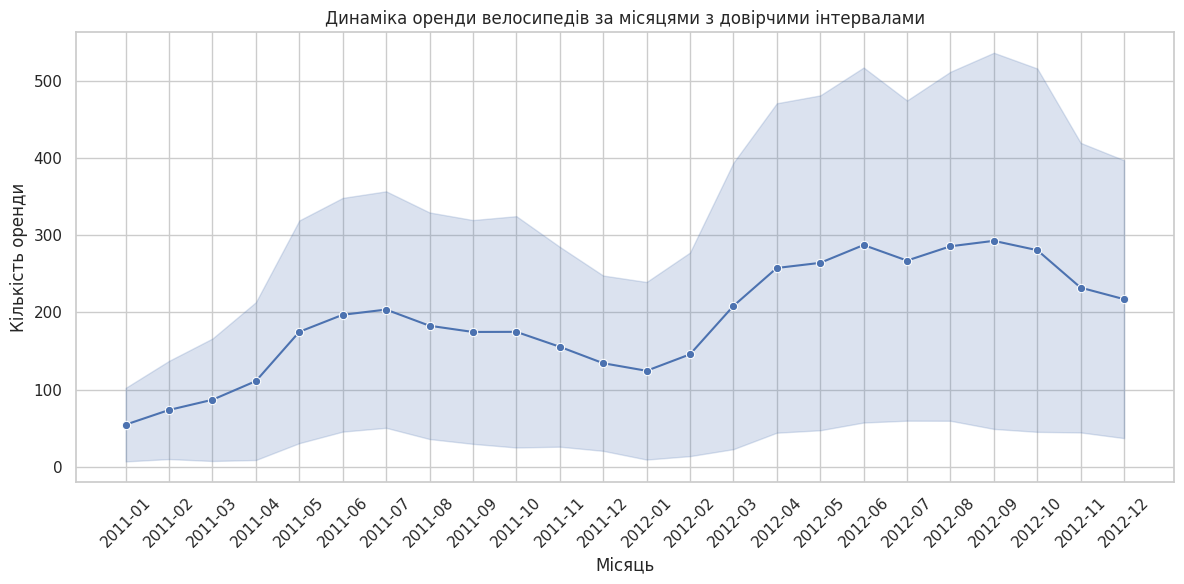

In [4]:

plt.figure(figsize=(12, 6))

sns.lineplot(df, x='month_year', y='count', errorbar='sd', marker='o')
plt.title('Динаміка оренди велосипедів за місяцями з довірчими інтервалами')
plt.xlabel('Місяць')
plt.ylabel('Кількість оренди')
plt.xticks(rotation=45)
plt.tight_layout();

Найбільш хаотичним періодом виявився проміжок із квітня по листопад 2012 року. Через максимальне стандартне відхилення в цей час спостерігається великий розрив між «успішними» та «тихими» днями в межах місяця. Натомість у 2011 році та в зимові місяці показники були набагато компактнішими.

## Завдання 2: Порівняння стилів - Pandas vs Seaborn гістограма

**Завдання:**
Побудуйте гістограму розподілу температури двома способами - з Pandas та Seaborn - та порівняйте візуальний вигляд. Задайте однакову кількість бінів в цих візуалізаціях, відмінну від стандартної. В візуалізації Seaborn додайте параметр при побудові `kde=True`.

**Функція Seaborn: `sns.histplot()`**

Можна побудувати окремо два графіки. Але для тих, хто хоче складніше - побудуйте ці 2 графіки на 1 фігурі.

**Дайте відповідь на питання:**
1. Яка візуальна різниця між Pandas та Seaborn гістограмами?
2. Що за лінія додаткова на графіку в Seaborn? Як вона називається і як ви б її описали своїми словами?

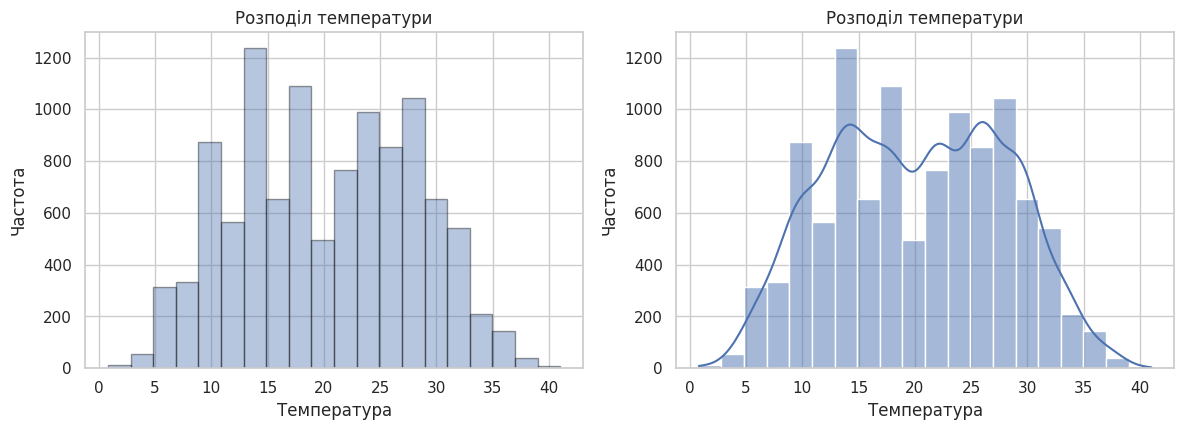

In [5]:
plt.figure(figsize=(12, 8))

#Графік Pandas
plt.subplot(2, 2, 1)
df['temp'].plot.hist(
    bins=20,
    alpha=0.4,
    edgecolor='black',
    title='Розподіл температури',
    xlabel='Температура',
    ylabel='Частота'
)

#Графік Seaborn
plt.subplot(2, 2, 2)
sns.histplot(df['temp'], bins=20, kde=True)
plt.title('Розподіл температури')
plt.xlabel('Температура')
plt.ylabel('Частота')

plt.tight_layout()
plt.show()

**Яка візуальна різниця між Pandas та Seaborn гістограмами?**

Гістограма в Pandas виглядає дуже просто і найчастіше не має підписів осей, якщо їх не додати самостійно. Натомість Seaborn робить це автоматично, пропонує приємніші, м'якіші кольори та додає легку прозорість, крізь яку чудово видно сітку графіка.

**Що за додаткова лінія на графіку в Seaborn? Як вона називається і як ви б її описали своїми словами?**

Це згладжена крива розподілу (KDE). Своїми словами, це плавна візуалізація форми даних, яка дозволяє легко оцінити загальний характер розподілу — наприклад, його симетричність чи наявність кількох піків — без відволікання на розриви між стовпчиками гістограми.

## Завдання 3: Box Plot порівняння - Pandas vs Seaborn

**Завдання:**
Побудуйте box plot для кількості погодинних оренд велосипедів за погодними умовами з Pandas та Seaborn.

**Функція Seaborn: `sns.boxplot()`**

Можна побудувати окремо два графіки. Але для тих, хто хоче складніше - побудуйте ці 2 графіки на 1 фігурі.

Просунуте доповнення:
- підпишіть погодні умови їх інтерпретацією з опису даних в обох графіках

**Дайте відповідь на питання:**
- Яка візуальна різниця між Pandas та Seaborn бокс-плотами?

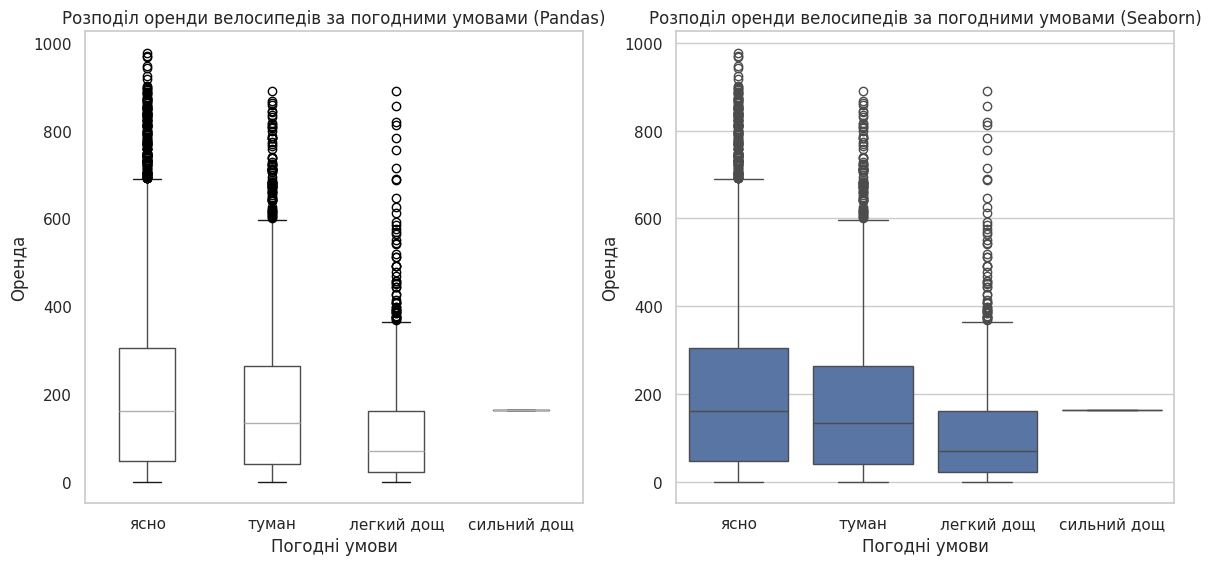

In [6]:
plt.figure(figsize=(12, 6))

#Графік Pandas
ax1 = plt.subplot(1, 2, 1)
df.boxplot(column='count', by='weather', grid=False, ax=ax1)
plt.title('Розподіл оренди велосипедів за погодними умовами (Pandas)')
plt.suptitle('')
plt.xlabel('Погодні умови')
plt.ylabel('Оренда')
plt.xticks([1, 2, 3, 4], ['ясно', 'туман', 'легкий дощ', 'сильний дощ'])

#Графік Seaborn
plt.subplot(1, 2, 2)
sns.boxplot(data=df, x='weather', y='count')
plt.title('Розподіл оренди велосипедів за погодними умовами (Seaborn)')
plt.xlabel('Погодні умови')
plt.ylabel('Оренда')
plt.xticks([0, 1, 2, 3], ['ясно', 'туман', 'легкий дощ', 'сильний дощ'])

plt.tight_layout()
plt.show()

**Яка візуальна різниця між Pandas та Seaborn бокс-плотами?**

Pandas зазвичай малює чорно-білі графіки, тоді як Seaborn автоматично використовує кольорові палітри, що робить візуалізацію набагато привабливішою та зручнішою для сприйняття. Крім того, для побудови бокс-плота за категоріями в Pandas доводиться застосовувати параметр by, який створює додаткові технічні заголовки, тоді як у Seaborn групування реалізовано значно елегантніше через параметри x та y.

<!-- - -->
## Завдання 4: Heatmap кореляційної матриці

**Завдання:**
Створіть із Seaborn кореляційну матрицю з забарвленням heatmap (колір відповідає величині значення в клітинці) числових змінних в наших даних з анотаціями значень.

**Дайте відповіді на питання по графіку:**
1. Які змінні найсильніше корелюють з загальною кількістю оренди (count)?
2. Яка кореляція між temp та atemp? Чому?
3. Які змінні мають негативну кореляцію?


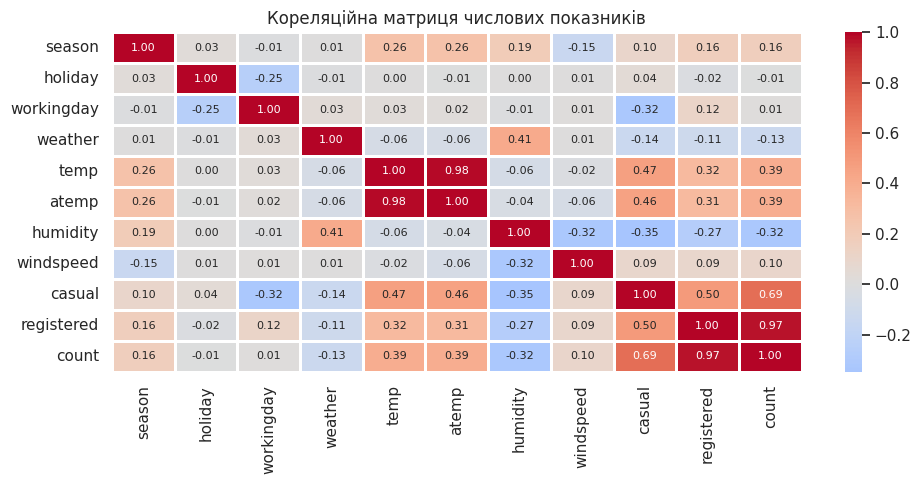

In [7]:
corr = df[['season', 'holiday', 'workingday', 'weather',
           'temp', 'atemp', 'humidity', 'windspeed',
           'casual', 'registered', 'count']].corr()

plt.figure(figsize=(10, 5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            linewidths=1, annot_kws={'size': 8})
plt.title('Кореляційна матриця числових показників')
plt.tight_layout()
plt.show()

**Які змінні найсильніше корелюють з загальною кількістю оренди (count)?**

Найвищі показники спостерігаються для таких параметрів:

**registered (0.97):** це свідчить про те, що загальний обсяг оренди майже повністю залежить від активності постійних користувачів.

**casual (0.69):** також демонструє сильну позитивну кореляцію, вказуючи на помітний внесок випадкових клієнтів.

**temp та atemp (0.39):** температура має помірний прямий вплив — із потеплінням зростає і потік людей.

**Яка кореляція між temp та atemp? Чому?**

Коефіцієнт кореляції між фактичною температурою (temp) та відчутною (atemp) дорівнює 0.98, оскільки в більшості випадків ці показники майже ідентичні.

**Які змінні мають негативну кореляцію?**

humidity та count (-0.32)
weather та count (-0.13)
holiday та workingday (-0.25)
humidity та windspeed (-0.32)

## Завдання 5: Violin Plot для глибокого аналізу розподілів

**Завдання:**
Створіть violin plot для аналізу розподілу оренди за кварталами.

Дайте відповіді на питання:

**Питання для інтерпретації:**
1. Що показує "товщина" violin plot?
2. В якому кварталі найбільша варіабельність оренди?
3. Яка перевага violin plot над звичайним box plot?


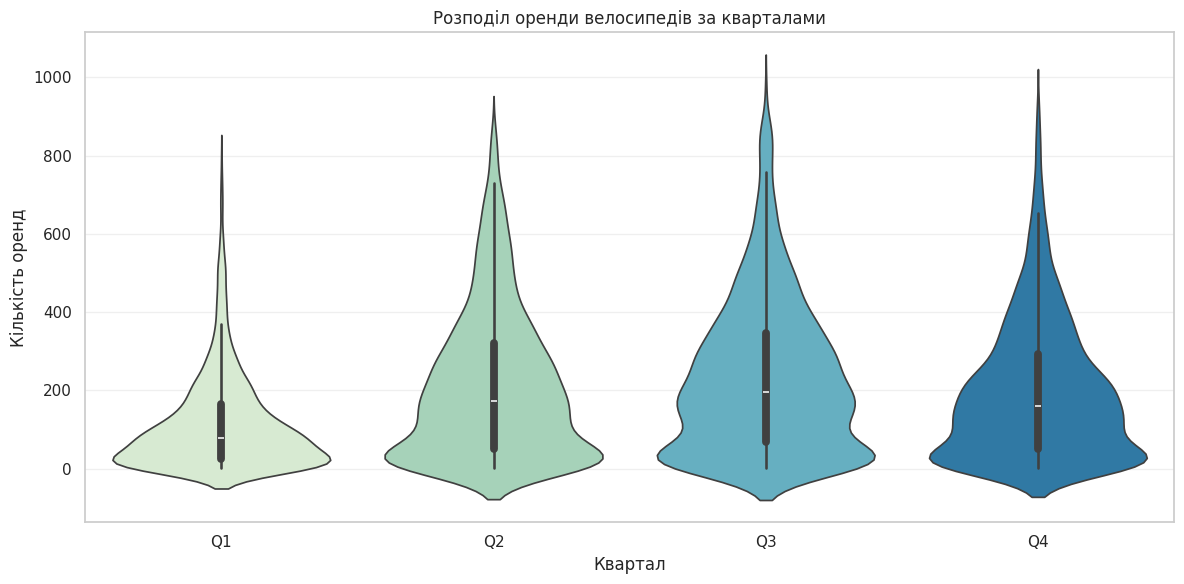

In [9]:
quarter_labels = {1: 'Q1', 2: 'Q2', 3: 'Q3', 4: 'Q4'}
df['quarter'] = df['season'].map(quarter_labels)

plt.figure(figsize=(12, 6))
sns.violinplot(data=df, x='quarter', y='count', hue='quarter', palette='GnBu', legend=False)
plt.title('Розподіл оренди велосипедів за кварталами')
plt.xlabel('Квартал')
plt.ylabel('Кількість оренд')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

**Що показує "товщина" violin plot?**

Ширина «скрипки» відображає щільність розподілу та частоту появи певних значень. Що ширша конкретна ділянка графіку, то більше спостережень припадає на цей рівень оренди.

**В якому кварталі найбільша варіабельність оренди?**

Найвищий рівень варіативності зафіксовано в 3-му кварталі (Q3). Це легко помітити за сильним вертикальним витягненням «скрипки» та широким розмахом між мінімальними й максимальними показниками.

**Яка перевага violin plot над звичайним box plot?**

Класичний box plot демонструє лише базові статистичні маркери (медіану, межі, викиди), залишаючись доволі узагальненим. Натомість violin plot дає набагато повнішу картину, візуалізуючи реальну форму та характер розподілу даних.

## Завдання 6 : Pairplot для мультиваріативного аналізу

**Завдання:**
Створіть pairplot для аналізу взаємозв'язків між ключовими змінними `'temp', 'humidity', 'windspeed', 'count'` . В якості візуальної розбивки за категоріями (параметр `hue`) додайте season (квартал).

Дайте відповіді на питання:

**Питання для інтерпретації:**
1. Між якими змінними спостерігається найсильніший лінійний зв'язок?
2. Яка характеристика найбільше відрізняється між кварталами?

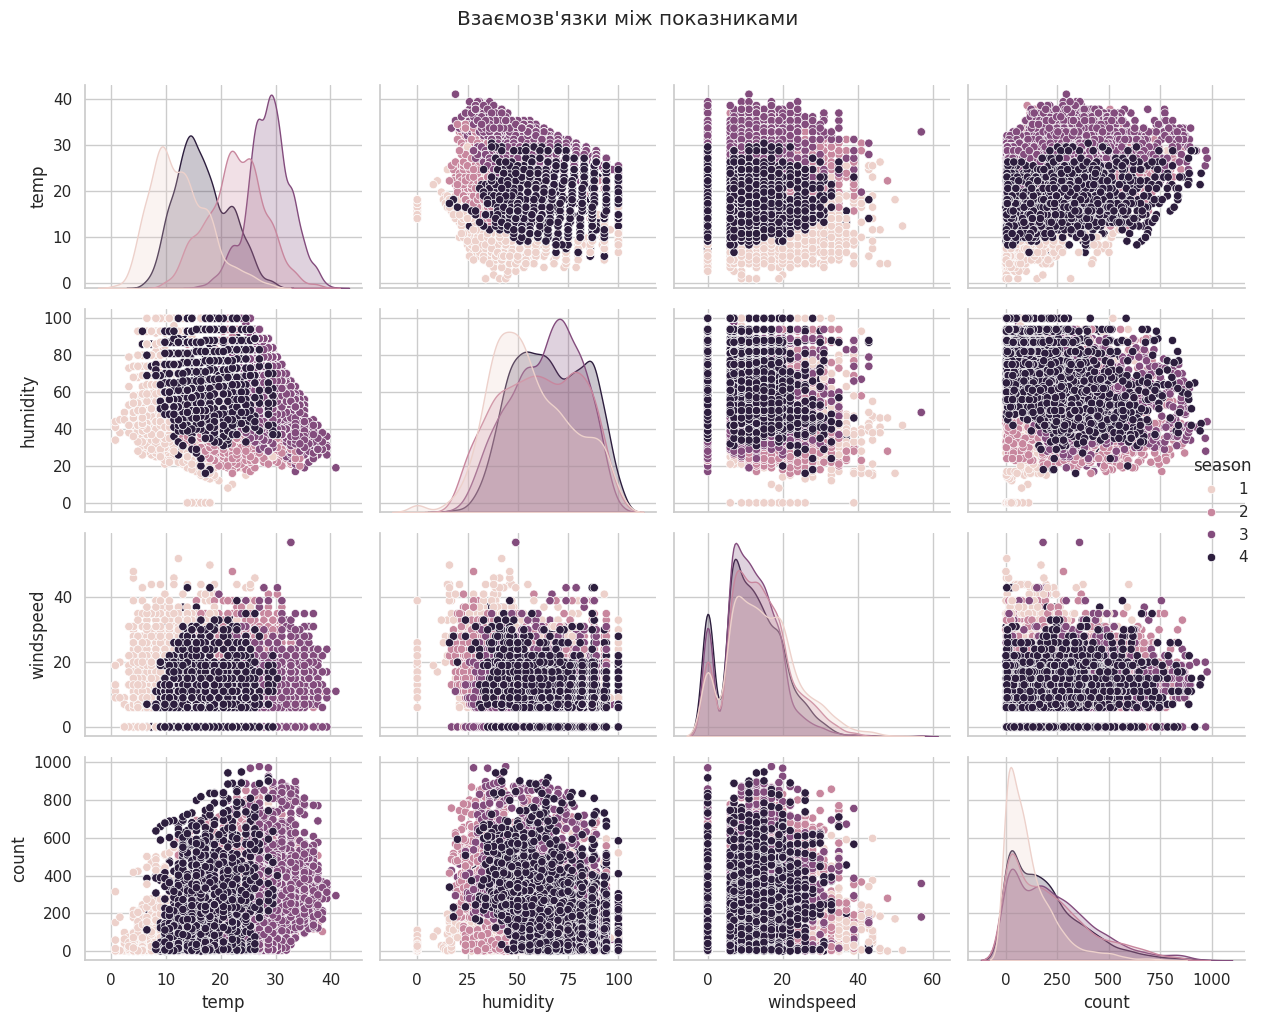

In [10]:
sample_df = df[['temp', 'humidity', 'windspeed', 'count', 'season']]

sns.pairplot(sample_df, hue='season', height=2.5, aspect=1.2)
plt.suptitle("Взаємозв'язки між показниками", y=1.02)
plt.tight_layout()
plt.show()

**Між якими змінними спостерігається найсильніший лінійний зв'язок?**

Найтісніший лінійний зв'язок зафіксовано між температурою (temp) та кількістю оренд (count). На відповідній діаграмі розсіювання чітко простежується висхідний тренд: зі зростанням температури точки з показниками оренди розташовуються вище і щільніше.

**Яка характеристика найбільше відрізняється між кварталами?**

Найсильніші відмінності між кварталами демонструє температура (temp), що чудово видно на графіках розподілу (на діагоналі), де сезонні криві майже не перетинаються. Суттєво різниться й показник оренди (count): у зимовий період (1-й квартал) пік розподілу зміщений у бік мінімальних значень, тоді як у теплі місяці — до максимальних.

## Завдання 7: Joint Plot для детального аналізу двох змінних

**Завдання:**
Проаналізуйте залежність між температурою та орендою за допомогою joint plot. В якості візуальної розбивки за категоріями (параметр `hue`) додайте `workingday`.

Дайте відповіді на питання:

**Питання для інтерпретації:**
1. Що показують графіки по краях?
2. Чи є різниця у поведінці користувачів у робочий і неробочий день?

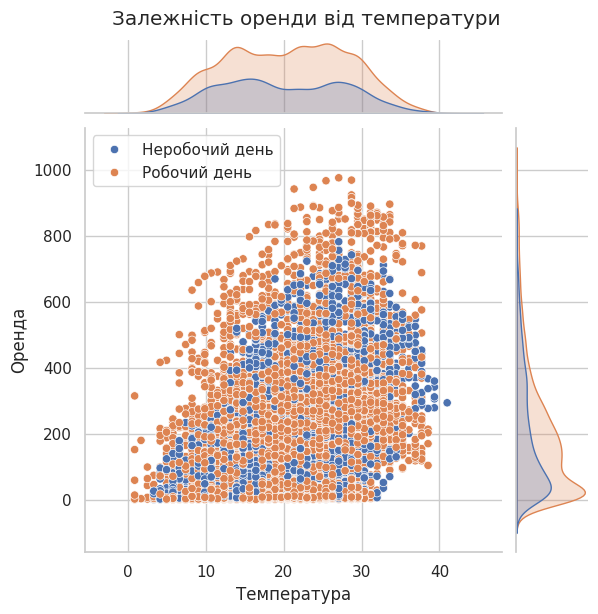

In [11]:
df['workingday_label'] = df['workingday'].map({
    0: 'Неробочий день',
    1: 'Робочий день'
})

g = sns.jointplot(data=df, x='temp', y='count', hue='workingday_label')
g.fig.suptitle('Залежність оренди від температури', y=1.02)
g.set_axis_labels('Температура', 'Оренда')
g.ax_joint.legend(title='');

**Що показують графіки по краях?**

На графіках уздовж країв (маргінальних) відображено одновимірний розподіл кожної окремої змінної. Зокрема, верхня діаграма ілюструє розподіл температури, а права — кількості оренд.

**Чи є різниця у поведінці користувачів у робочий і неробочий день?**

Для обох типів днів спостерігається спільна тенденція: попит зростає із підвищенням температури. Сині точки відповідають за робочі дні, а зелені — за вихідні. Оскільки синіх позначок візуально значно більше, це свідчить про те, що переважна більшість оренд припадає на будні, тобто люди частіше використовують велосипеди як транспорт для доїзду на роботу чи навчання.